In [12]:
include("visr_mod.jl")
using CSV,DataFrames,GMT,NCDatasets

In [10]:
function write_to_netcdf(filename::String, lon::Vector{<:Real}, lat::Vector{<:Real}, values::Matrix{<:Real}; 
    lon_units::String="degrees_east", lat_units::String="degrees_north", 
    value_name::String="z", value_units::String=" ", value_desc::String=" ")

ds = NCDataset(filename, "c")

# Define dimensions
defDim(ds, "lon", length(lon))
defDim(ds, "lat", length(lat))

# Define variables
lon_var = defVar(ds, "lon", Float64, ("lon",))
lat_var = defVar(ds, "lat", Float64, ("lat",))
value_var = defVar(ds, value_name, Float64, ("lon", "lat"))  # (lon, lat) order

# Add attributes to variables
lon_var.attrib["units"] = lon_units
lon_var.attrib["long_name"] = "longitude"
lat_var.attrib["units"] = lat_units
lat_var.attrib["long_name"] = "latitude"
value_var.attrib["units"] = value_units
value_var.attrib["long_name"] = value_desc

# Write data to variables
lon_var[:] = lon
lat_var[:] = lat
value_var[:, :] = values  # Write values in (lon, lat) order

# Close the NetCDF file
close(ds)

end

write_to_netcdf (generic function with 1 method)

In [18]:
function read_strain_output_visr(filepath::String)
 
    # ------------------------------------------------------------------ #
    # 1.  Raccoglie tutte le righe nel vettore raw        #
    # ------------------------------------------------------------------ #
    #longitude latitude      vx+dvx       vy+dvy    cxy         w+dw         exx+dexx         exy+dexy         eyy+deyy         emax+demax       emin+demin        shr+dshr         azi+dazi        dilat+ddilat     dis.    weight    chisq   nsite
    # Nomi dei 27 campi dopo lon/lat (nell'ordine in cui appaiono nel file)
    field_names = [
        :vx, :dvx, :vy, :dvy, :cxy,
        :w, :dw,
        :exx, :dexx, :exy, :dexy, :eyy, :deyy,
        :emax, :demax, :emin, :demin,
        :shr, :dshr, :azi, :dazi,
        :dilat, :ddilat,
        :dis, :weight, :chisq, :nsite
    ]
    n_fields = length(field_names)   # 27
 
    # Struttura temporanea per accumulare i dati riga per riga
    lons_raw    = Float64[]
    lats_raw    = Float64[]
    data_raw    = Vector{Float64}[]  # ogni elemento è un vettore di n_fields valori
    index_raw   = Int[]
 
    open(filepath, "r") do io
        readline(io)   # salta la riga di intestazione
        readline(io)   # salta la seconda riga

        for line in eachline(io)
            isempty(strip(line)) && continue
 
            if occursin("index", line)
                # Formato: "lon  lat  index = N"
                parts = split(line)
                lon   = parse(Float64, parts[1])
                lat   = parse(Float64, parts[2])
                idx   = parse(Int,     parts[end])
                push!(lons_raw,  lon)
                push!(lats_raw,  lat)
                push!(index_raw, idx)
                push!(data_raw,  fill(NaN, n_fields))
            else
                # Formato: "lon  lat  v1  v2  ... v27"
                parts = split(line)
                lon   = parse(Float64, parts[1])
                lat   = parse(Float64, parts[2])
                vals  = [parse(Float64, parts[i+2]) for i in 1:n_fields]
                push!(lons_raw,  lon)
                push!(lats_raw,  lat)
                push!(index_raw, -1) # -1 valore dove non ci sono righe "index="
                push!(data_raw,  vals)
            end
        end
    end
 
    # ------------------------------------------------------------------ #
    # 2.  Determina la griglia                                             #
    # ------------------------------------------------------------------ #
    lons_uniq = sort(unique(lons_raw))   # N_lon valori crescenti
    lats_uniq = sort(unique(lats_raw))   # N_lat valori crescenti

    longrid=[lons_uniq[i] for i in axes(lons_uniq,1), _ in axes(lats_uniq,1)]
    latgrid=[lats_uniq[j] for _ in axes(lons_uniq,1), j in axes(lats_uniq,1)]

    N_lon = length(lons_uniq)
    N_lat = length(lats_uniq)
 
    # Indici rapidi per lon/lat → posizione nella griglia
    lon_idx = Dict(v => i for (i, v) in enumerate(lons_uniq))
    lat_idx = Dict(v => i for (i, v) in enumerate(lats_uniq))
 
    # ------------------------------------------------------------------ #
    # 3.  Riempie le matrici 2D  (N_lon × N_lat)                          #
    # ------------------------------------------------------------------ #
    # Inizializza tutte le matrici a NaN
    matrices = [fill(NaN, N_lon, N_lat) for _ in 1:n_fields]
 
    # Trova tutti i valori di index presenti (eccetto -1)
    all_indices = sort(unique(index_raw))
    extra_indices = filter(x -> x != -1, all_indices)
 
    # Matrici booleane per ogni index != -1
    index_masks = Dict{Int, Matrix{Bool}}(
        k => fill(false, N_lon, N_lat) for k in extra_indices
    )
 
    for k in 1:length(lons_raw)
        i = lon_idx[lons_raw[k]]
        j = lat_idx[lats_raw[k]]
        idx = index_raw[k]
 
        # Riempie i campi fisici (NaN già presenti per index != -1)
        if idx == -1
            for f in 1:n_fields
                matrices[f][i, j] = data_raw[k][f]
            end
        end
 
        # Aggiorna la maschera booleana per i valori di index != -1
        if idx != -1
            index_masks[idx][i, j] = true
        end
    end
 
    # ------------------------------------------------------------------ #
    # 4.  Costruisce la NamedTuple di output                             #
    # ------------------------------------------------------------------ #
    # Associa ogni matrice al suo nome simbolico
    field_dict = Dict(field_names[f] => matrices[f] for f in 1:n_fields)
 
    return (
        # Coordinate
        lons   = lons_uniq,
        lats   = lats_uniq,
        longrid= longrid,
        latgrid=    latgrid,
 
        # Velocità
        vx     = field_dict[:vx],
        dvx    = field_dict[:dvx],
        vy     = field_dict[:vy],
        dvy    = field_dict[:dvy],
        cxy    = field_dict[:cxy],
 
        # Rotazione
        w      = field_dict[:w],
        dw     = field_dict[:dw],
 
        # Tensore di deformazione
        exx    = field_dict[:exx],
        dexx   = field_dict[:dexx],
        exy    = field_dict[:exy],
        dexy   = field_dict[:dexy],
        eyy    = field_dict[:eyy],
        deyy   = field_dict[:deyy],
 
        # Strain principali
        emax   = field_dict[:emax],
        demax  = field_dict[:demax],
        emin   = field_dict[:emin],
        demin  = field_dict[:demin],
 
        # Shear e azimut
        shr    = field_dict[:shr],
        dshr   = field_dict[:dshr],
        azi    = field_dict[:azi],
        dazi   = field_dict[:dazi],
 
        # Dilatazione
        dilat  = field_dict[:dilat],
        ddilat = field_dict[:ddilat],
 
        # Statistiche/metadati
        dis    = field_dict[:dis],
        weight = field_dict[:weight],
        chisq  = field_dict[:chisq],
        nsite  = field_dict[:nsite],
 
        # Maschere booleane per index != 1
        index_masks = index_masks,
    )
end


read_strain_output_visr (generic function with 1 method)

In [2]:
DataSet=CSV.read("./combined.cmm4",DataFrame,delim=' ', ignorerepeated=true, header=false);

In [6]:
lonmean=mean(DataSet[:,2])
latmean=mean(DataSet[:,3])
print(lonmean)
print(" ")
print(latmean)

16.55692516373664 40.30759362583592

In [7]:
x_stations=Float64[];
y_stations=Float64[];
for i in 1:size(DataSet,1)
    x_temp, y_temp = llxy(mean(DataSet[:,2]), mean(DataSet[:,3]), [DataSet[i,2]], [DataSet[i,3]])
    push!(x_stations,x_temp[1])
    push!(y_stations,y_temp[1])
end

In [8]:
"""
gmtset(MAP_FRAME_TYPE="plain")
GMT.basemap(J="M8c",region=[-10,40,25,60])
GMT.coast!(resolution = :intermediate)
GMT.scatter!(DataSet[:,2],DataSet[:,3],S="c1p",fill="red",show=true)
"""
areas,indices_fallback,radii,polygons_x,polygons_y=compute_voronoi_areas(x_stations,y_stations)
# GMT.histogram(areas,region=[minimum(areas),maximum(areas)+10^6,0,10],show=true)
circles_x=Float64[]
circles_y=Float64[]

angle_range=0.0:1:360
for i=1:length(indices_fallback)
    indx=indices_fallback[i]

    x_temp=x_stations[indx]
    y_temp=y_stations[indx]
    radius_temp=radii[i]

    for angle in angle_range
        val_x=x_temp+ (radius_temp*cosd(angle))
        val_y=y_temp+ (radius_temp*sind(angle))
        push!(circles_x,val_x)
        push!(circles_y,val_y)
    end
    push!(circles_x,NaN)
    push!(circles_y,NaN)
end
#cpt = makecpt(cmap="turbo", range="0/1000000", D="o")
#GMT.scatter(x_stations,y_stations,region=[-2000,2000,-2000,2000],J="X8c",S="c2p", zcolor=areas, cmap=cpt)
#colorbar!()
#GMT.plot!(polygons_x,polygons_y)
#GMT.plot!(circles_x,circles_y,pen="1p,blue",show=true)
#GMT.scatter!(x_stations[indices_fallback],y_stations[indices_fallback],S="c0.1p", fill="blue",show=true)

stations = Vector{Station}()

for i =1:size(DataSet,1)
    temp_station=Station(DataSet[i,2],DataSet[i,3],x_stations[i],y_stations[i],DataSet[i,4],DataSet[i,5],DataSet[i,6],DataSet[i,7],areas[i])
    push!(stations,temp_station)
end

parameters=Parameters(lonmean,latmean,2.15,1,100,1,24)
lons,lats,results=visr_mod(parameters, stations, 25.0, 30.0, 34.0, 38.0, 0.1, 0.1)

([25.0, 25.1, 25.2, 25.3, 25.4, 25.5, 25.6, 25.7, 25.8, 25.9  …  29.1, 29.2, 29.3, 29.4, 29.5, 29.6, 29.7, 29.8, 29.9, 30.0], [34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0, 34.0  …  38.0, 38.0, 38.0, 38.0, 38.0, 38.0, 38.0, 38.0, 38.0, 38.0], VisrSolution[VisrSolution(2, 0.0, 0.0, [0.0, 0.0, 0.0], 0.0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], 0.0, 0.0, 0.0, 0.0, 0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), VisrSolution(2, 0.0, 0.0, [0.0, 0.0, 0.0], 0.0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], 0.0, 0.0, 0.0, 0.0, 0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), VisrSolution(2, 0.0, 0.0, [0.0, 0.0, 0.0], 0.0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], 0.0, 0.0, 0.0, 0.0, 0, [0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), VisrSolution(2, 0.0, 0.0, [0

In [13]:
I2_vec=Float64[]
for i=1:length(results)
    if(results[i].status == 0)
        I2=sqrt((results[i].strain_rate[1].^2) + (2*(results[i].strain_rate[2].^2)) + (results[i].strain_rate[3].^2))
        #print(I2)
        #print('\n')
    else
        #I2=-(results[i].status)*10
        I2=0
    end
    push!(I2_vec,I2)
end

lon_unique=unique(lons)
lat_unique=unique(lats)

I2_matrix=reshape(I2_vec,length(lon_unique),length(lat_unique))

write_to_netcdf("./ESecondInvariant.nc",lon_unique,lat_unique,I2_matrix)#nstr/yr

closed Dataset

In [27]:
output=read_strain_output_visr("./strain.out")

Lon=output.lons 
Lat=output.lats 
LonGrid=output.longrid 
LatGrid=output.latgrid 
ExxGrid=output.exx     # matrice (N_lon × N_lat) dello strain exx
ExyGrid=output.exy         # matrice (N_lon × N_lat) dello strain exx
EyyGrid=output.eyy     # matrice (N_lon × N_lat) dello strain exx

ESecondInvariantFORTRAN=sqrt.(ExxGrid.^2+EyyGrid.^2+2*ExyGrid.^2);

write_to_netcdf("./ESecondInvariantFORTRAN.nc",Lon,Lat,ESecondInvariantFORTRAN)#nstr/yr

closed Dataset

In [28]:
my_design=Matrix{Float64}[]
for i in 1:length(results)
    if (sqrt((results[i].strain_rate[1].^2) + (2*(results[i].strain_rate[2].^2)) + (results[i].strain_rate[3].^2)) > (600)) & (results[i].status==0)
        my_design=results[i].design
    end
end
my_design

82×6 Matrix{Float64}:
 1.98789   0.0         15.6243    49.6297    0.0      49.6297
 0.0       1.95038      0.0       15.3295   48.6933  -15.3295
 2.31449   0.0       -351.457     98.5274    0.0      98.5274
 0.0       2.17834      0.0     -330.783    92.7317  330.783
 0.583863  0.0        -86.1795    27.747     0.0      27.747
 0.0       0.652553     0.0      -96.3183   31.0114   96.3183
 1.33772   0.0        -85.3913   143.501     0.0     143.501
 0.0       1.56067      0.0      -99.6232  167.418    99.6232
 0.910184  0.0        -27.2951   118.243     0.0     118.243
 0.0       1.01132      0.0      -30.3279  131.381    30.3279
 ⋮                                                     ⋮
 0.0       4.60917      0.0     -268.451   161.802   268.451
 0.240891  0.0         19.1519    40.6759    0.0      40.6759
 0.0       0.361336     0.0       28.7279   61.0138  -28.7279
 0.135474  0.0         21.5028    13.0735    0.0      13.0735
 0.0       0.129408     0.0       20.54     12.4881  -20.5

In [21]:
"""

region=[-10.0, 40.0, 30.0, 50.0]
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="./STRrate.cpt", range="0/800")
GMT.basemap(region=region,J="M15c")
GMT.grdimage!("./ESecondInvariant.nc", cmap=cpt,n="n")
GMT.colorbar!()
GMT.coast!(show=true)
#GMT.velo!([DataSet[:,2] DataSet[:,3] DataSet[:,4] DataSet[:,6] DataSet[:,5] DataSet[:,7]],Se="0.05/0.95",pen="0.012c,black")
#GMT.scatter!(DataSet[DataSet[:,5].<0.07,2],DataSet[DataSet[:,5].<0.07,3],S="c4p", fill="green")
lontext=DataSet[:,2] .+ (rand(length(DataSet[:,2])).*0.1)
lattext=DataSet[:,3]
#GMT.text!(x=lontext,y=lattext, String.(DataSet[:,1]),font="4p,white",show=true)

"""

"\nregion=[-10.0, 40.0, 30.0, 50.0]\ngmtset(MAP_FRAME_TYPE=\"plain\", PROJ_LENGTH_UNIT=\"c\")\ncpt = makecpt(cmap=\"./STRrate.cpt\", range=\"0/800\")\nGMT.basemap(region=region,J=\"M15c\")\nGMT.grdimage!(\"./ESecondInvariant.nc\", cmap=cpt,n=\"n\")\nGMT.colorbar!()\nGMT.coast!(show=true)\n#GMT.velo!(" ⋯ 96 bytes ⋯ "en=\"0.012c,black\")\n#GMT.scatter!(DataSet[DataSet[:,5].<0.07,2],DataSet[DataSet[:,5].<0.07,3],S=\"c4p\", fill=\"green\")\nlontext=DataSet[:,2] .+ (rand(length(DataSet[:,2])).*0.1)\nlattext=DataSet[:,3]\n#GMT.text!(x=lontext,y=lattext, String.(DataSet[:,1]),font=\"4p,white\",show=true)\n\n"

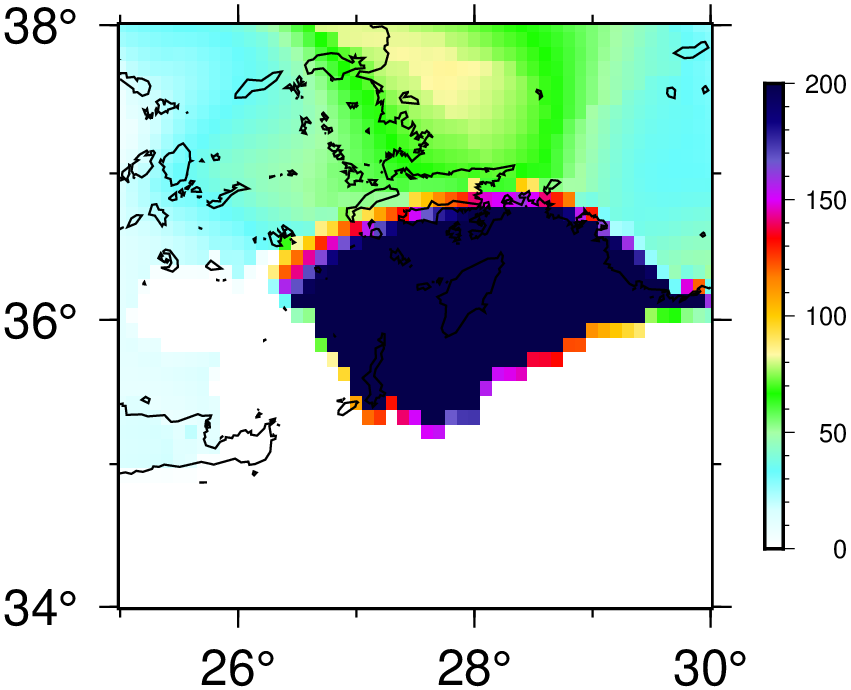

In [37]:
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="./STRrate.cpt", range="0/200")
GMT.basemap(region=[25.0, 30.0, 34.0, 38.0],J="M5c")
GMT.grdimage!("./ESecondInvariant.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)

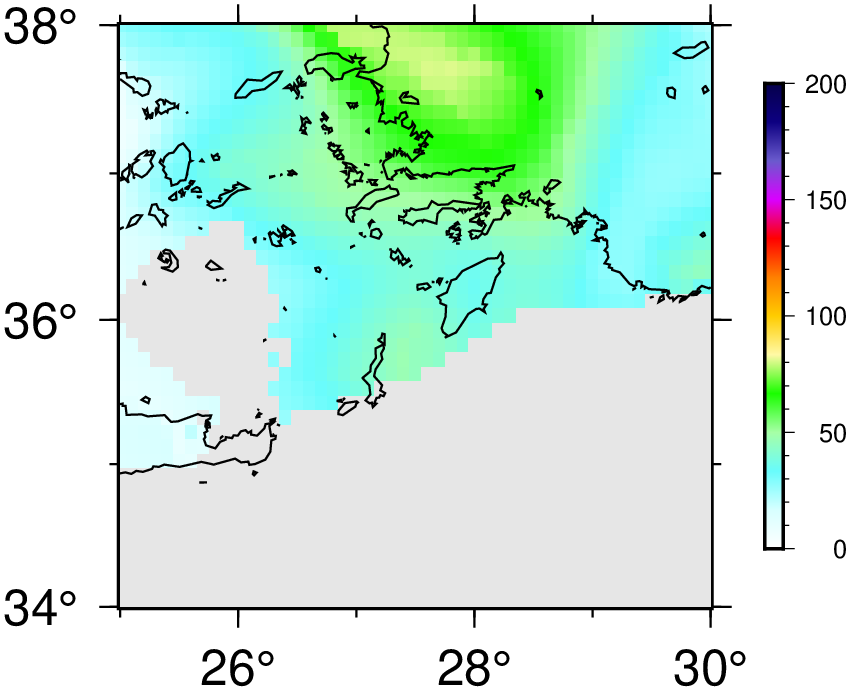

In [35]:

gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="./STRrate.cpt", range="0/200")
GMT.basemap(region=[25.0, 30.0, 34.0, 38.0],J="M5c")
GMT.grdimage!("./ESecondInvariantFORTRAN.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)


In [29]:
write_to_netcdf("./RediualSecondInv.nc",Lon,Lat,ESecondInvariantFORTRAN .- I2_matrix)#nstr/yr

closed Dataset

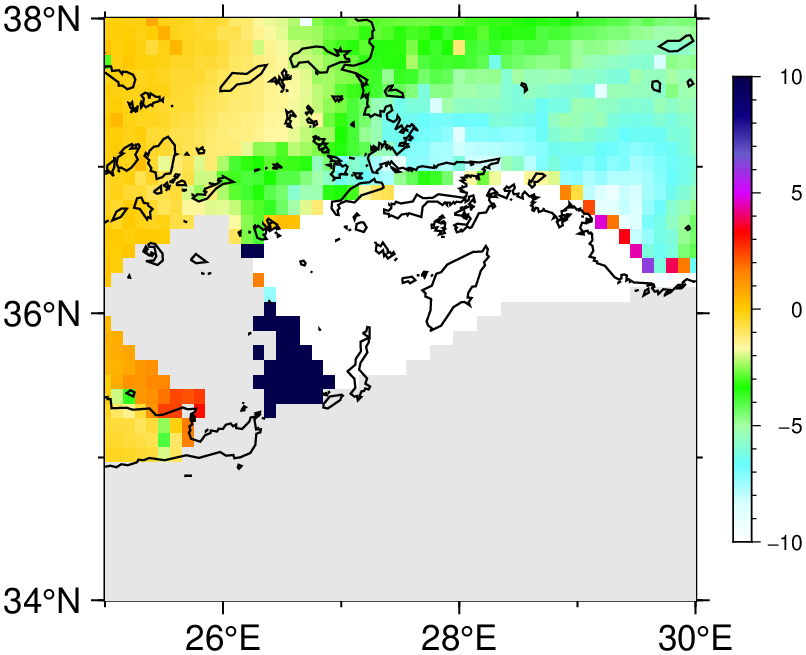

In [32]:
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="./STRrate.cpt", range="-10/10")
GMT.basemap(region=[25.0, 30.0, 34.0, 38.0],J="M5c")
GMT.grdimage!("./RediualSecondInv.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)

In [39]:
Chi_vec=Float64[]
for i=1:length(results)
    if(results[i].status == 0)
        Chi=results[i].chisq
    else
        Chi=NaN
    end
    push!(Chi_vec,Chi)
end

Chi_matrix=reshape(Chi_vec,length(lon_unique),length(lat_unique))


write_to_netcdf("./Chi.nc",lon_unique,lat_unique,Chi_matrix)#nstr/yr

closed Dataset

In [40]:
write_to_netcdf("./ChiFORTRAN.nc",Lon,Lat,output.chisq)#nstr/yr

write_to_netcdf("./ChiDIFF.nc",Lon,Lat,output.chisq .- Chi_matrix)#nstr/yr

closed Dataset

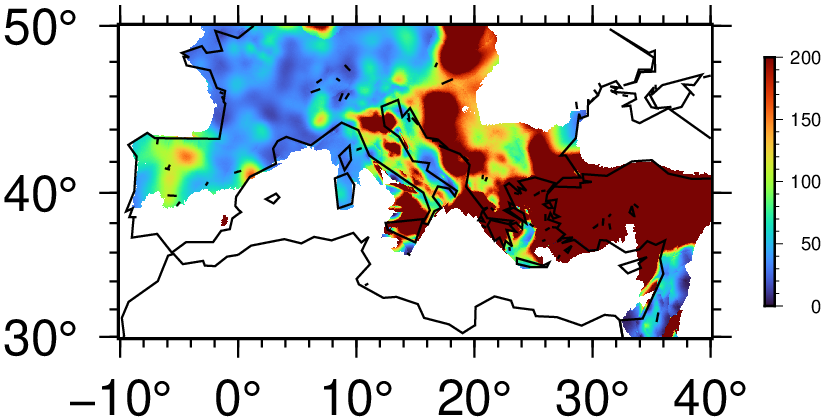

In [ ]:
"""
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="turbo", range="0/200", D="o")
GMT.basemap(region=region,J="M5c")
GMT.grdimage!("./Chi.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)
"""

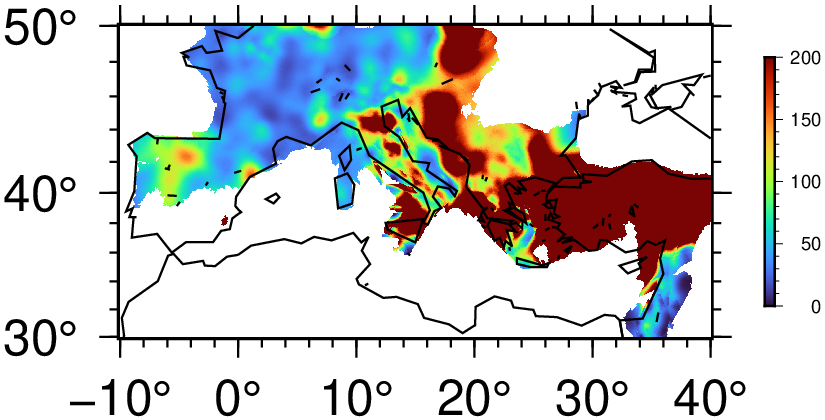

In [ ]:
"""
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="turbo", range="0/200", D="o")
GMT.basemap(region=region,J="M5c")
GMT.grdimage!("./ChiFORTRAN.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)
"""

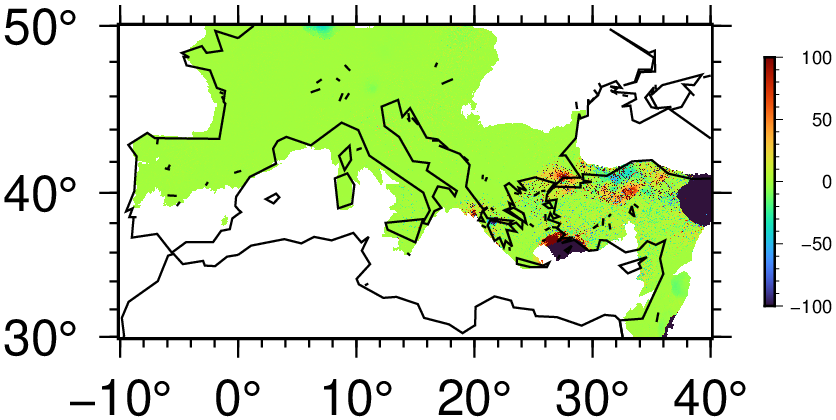

In [ ]:
"""
gmtset(MAP_FRAME_TYPE="plain", PROJ_LENGTH_UNIT="c")
cpt = makecpt(cmap="turbo", range="-100/100", D="o")
GMT.basemap(region=region,J="M5c")
GMT.grdimage!("./ChiDIFF.nc", cmap=cpt)
GMT.colorbar!()
GMT.coast!(show=true)
"""

In [ ]:
"""
maximum(output.chisq[.!isnan.(output.chisq[:])])
"""

33443.19

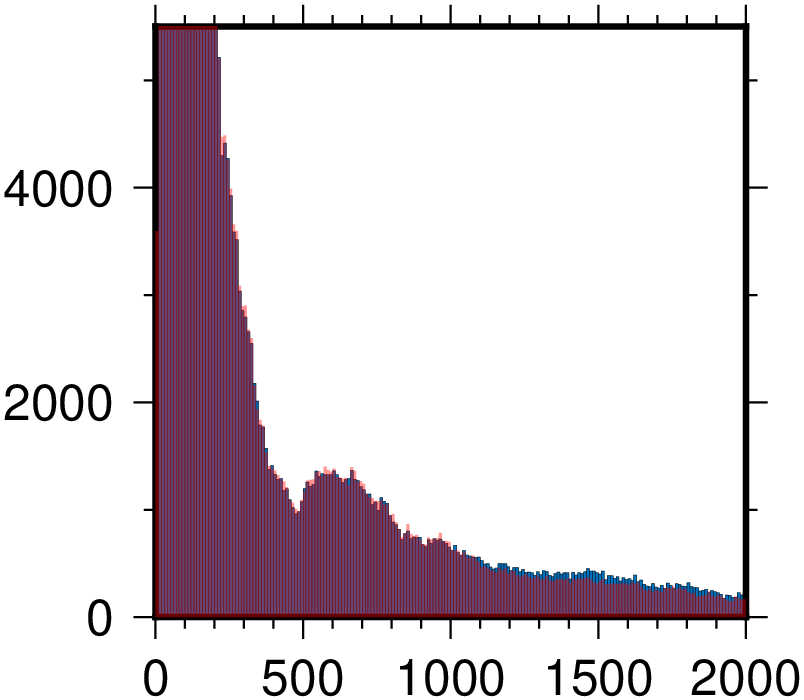

In [ ]:
"""
GMT.histogram(output.chisq[:],region=[0,2000,0,5500], bin=10, J="X5c")
GMT.histogram!(Chi_matrix[:],region=[0,2000,0,5500], bin=10, fill="red@60", show=true)
"""